# 03 — Exploration : marché, saisonnalité, comportement de prix

Le panel est construit. Avant de modéliser, il faut savoir **ce qui fait bouger
la demande en dehors du prix** : tout facteur ignoré ici deviendra un biais dans
l'estimation de l'élasticité.

Trois questions :
1. à quoi ressemble la trajectoire du marché (tendance, saison, chocs) ?
2. les vendeurs changent-ils leurs prix, et comment ?
3. voit-on quelque chose à l'œil nu dans la relation prix / quantité ?

In [1]:
%matplotlib inline
import sys
from pathlib import Path

# Le package est importable depuis le dossier notebooks/
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.25})

In [2]:
from optimization_pricing.dataset import load_panel

panel_cat = load_panel("category", processed=True)
panel_prod = load_panel("product", processed=True)
print("cadrage :", panel_cat.shape, "| modelisation :", panel_prod.shape)

cadrage : (2232, 26) | modelisation : (28636, 39)


## 1. La trajectoire du marché

Olist est en forte croissance sur la période. Cette tendance doit être
neutralisée : sinon, tout ce qui augmente avec le temps (y compris les prix)
apparaîtra corrélé positivement au volume — soit une élasticité positive,
économiquement absurde.

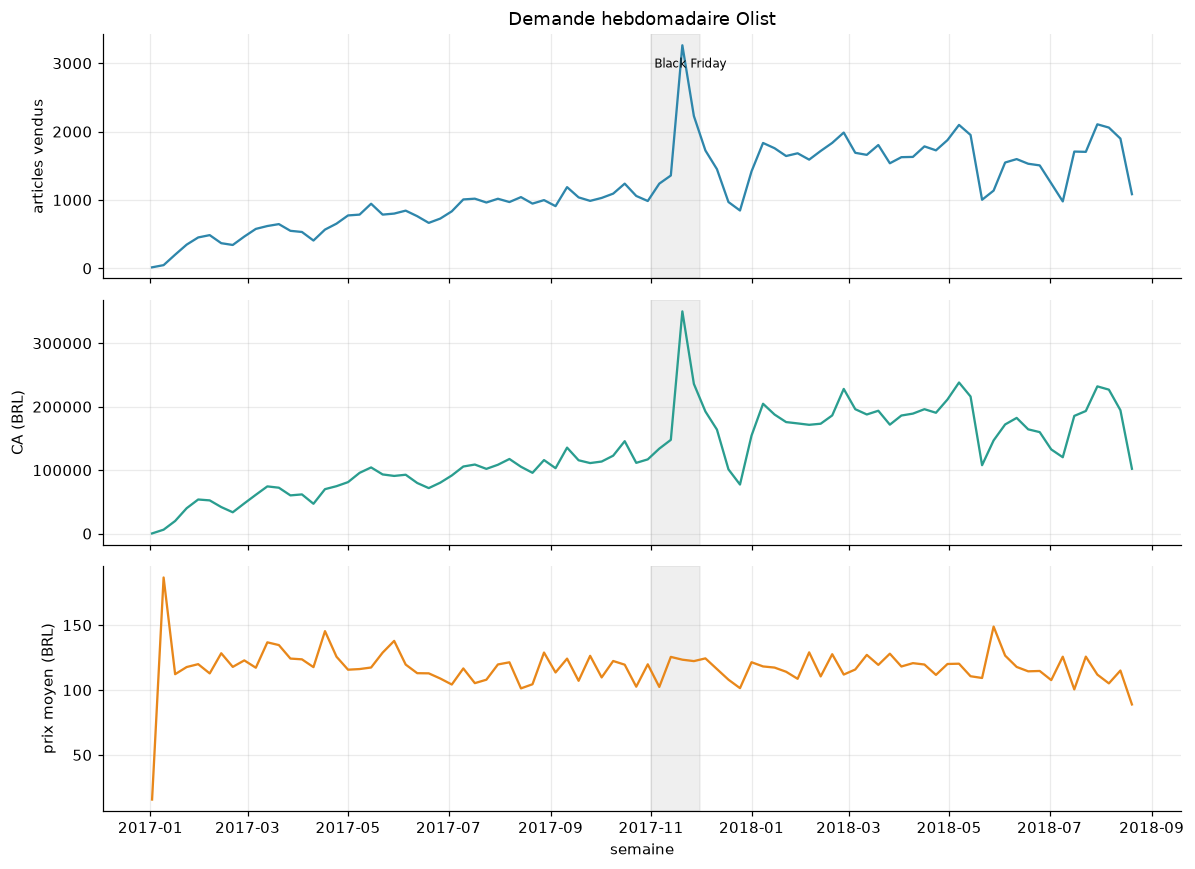

In [3]:
from optimization_pricing import plots

plots.plot_market_overview(panel_cat, save=True)
plt.show()

In [4]:
mensuel = panel_prod.groupby("month").agg(
    volume=("quantity", "sum"), prix_median=("price", "median"), produits=("product_id", "nunique")
)
mensuel["croissance volume"] = mensuel["volume"].pct_change()
mensuel.tail(10)

,volume,prix_median,produits,croissance volume
month,,,,
2017-11-01,5478,69.990,2055,0.620
2017-12-01,4191,74.000,1749,-0.235
2018-01-01,5496,74.900,2075,0.311
2018-02-01,5227,69.900,1996,-0.049
2018-03-01,5501,72.945,2136,0.052
2018-04-01,4952,72.990,2047,-0.100
2018-05-01,4924,70.000,1833,-0.006
2018-06-01,4029,74.000,1694,-0.182
2018-07-01,3619,69.990,1532,-0.102


## 2. La saisonnalité : le piège du Black Friday

En novembre, le volume explose **et** les prix bougent. Si le pic n'est pas
contrôlé, le modèle lit une hausse simultanée du prix et du volume et en conclut
que la demande augmente avec le prix.

C'est le rôle de l'indicatrice `is_holiday_season` et des effets fixes mois.

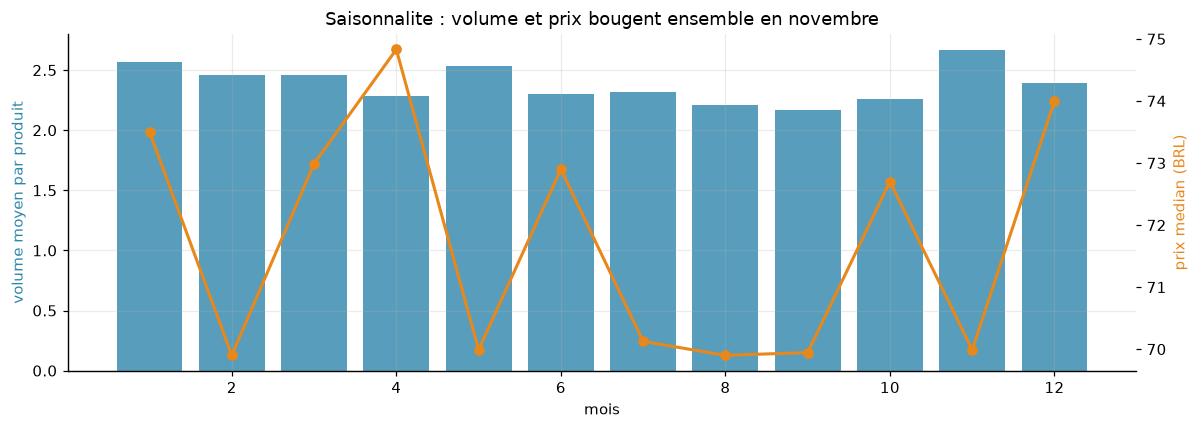

In [5]:
saison = panel_prod.groupby("month_of_year").agg(
    volume_moyen=("quantity", "mean"), prix_median=("price", "median")
)

fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(saison.index, saison["volume_moyen"], color="#2E86AB", alpha=0.8)
ax1.set_xlabel("mois")
ax1.set_ylabel("volume moyen par produit", color="#2E86AB")
ax2 = ax1.twinx()
ax2.plot(saison.index, saison["prix_median"], color="#E8871A", marker="o", lw=2)
ax2.set_ylabel("prix median (BRL)", color="#E8871A")
ax2.grid(False)
plt.title("Saisonnalite : volume et prix bougent ensemble en novembre")
plt.tight_layout()
plt.show()

## 3. Les vendeurs changent-ils leurs prix ?

C'est la question qui conditionne l'existence même du projet. Si personne ne
change jamais son prix, il n'y a rien à estimer.

Produits sans aucun changement de prix : 39.7%
Produits avec variation notable (>5 %) : 38.3%

count   5,933.000
mean        0.053
std         0.072
min         0.000
25%         0.000
50%         0.027
75%         0.081
max         0.834
Name: ecart_type_log_prix, dtype: float64


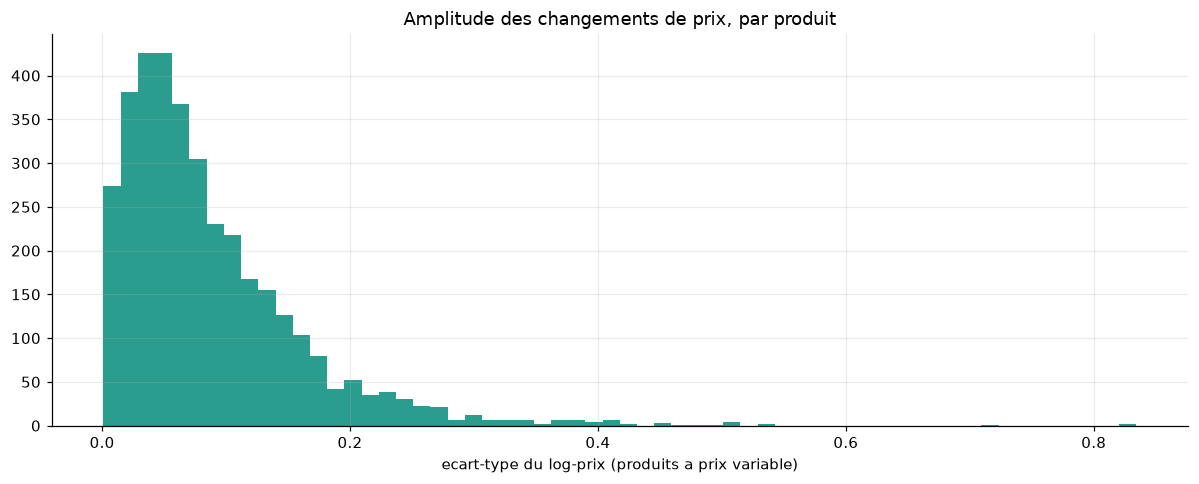

In [6]:
variation = (
    panel_prod.groupby("product_id")["log_price"]
    .agg(["std", "count"])
    .rename(columns={"std": "ecart_type_log_prix", "count": "mois_observes"})
    .fillna(0)
)

print(f"Produits sans aucun changement de prix : {(variation['ecart_type_log_prix'] < 0.001).mean():.1%}")
print(f"Produits avec variation notable (>5 %) : {(variation['ecart_type_log_prix'] > 0.05).mean():.1%}")
print()
print(variation["ecart_type_log_prix"].describe())

variation.loc[variation["ecart_type_log_prix"] > 0.001, "ecart_type_log_prix"].hist(
    bins=60, color="#2A9D8F"
)
plt.title("Amplitude des changements de prix, par produit")
plt.xlabel("ecart-type du log-prix (produits a prix variable)")
plt.tight_layout()
plt.show()

Une part significative des produits ne change **jamais** de prix : ils
n'apportent rien à l'identification (leurs observations sont absorbées par
l'effet fixe produit). Le signal vient de la minorité qui bouge — d'où
l'importance de ne pas diluer davantage l'échantillon.

Mouvements de prix observes : 6,444
  baisses : 44.7%  |  hausses : 55.3%
  amplitude mediane (valeur absolue) : 8.9%


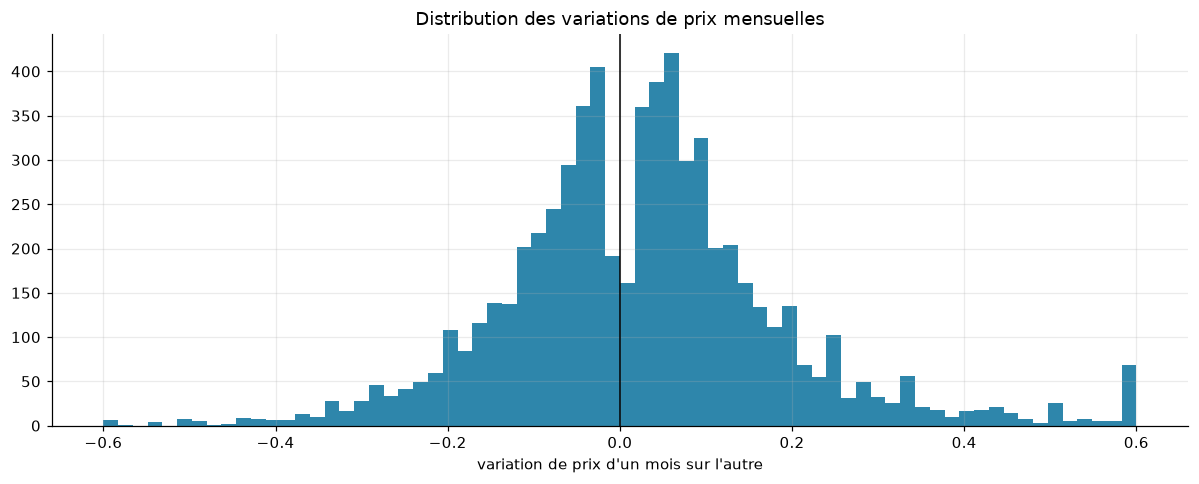

In [7]:
# Ampleur des mouvements : baisses (promos) vs hausses
mouvements = panel_prod.sort_values(["product_id", "month"]).copy()
mouvements["variation"] = mouvements.groupby("product_id")["price"].pct_change()
mouvements = mouvements.dropna(subset=["variation"])
notables = mouvements.loc[mouvements["variation"].abs() > 0.01, "variation"]

print(f"Mouvements de prix observes : {len(notables):,}")
print(f"  baisses : {(notables < 0).mean():.1%}  |  hausses : {(notables > 0).mean():.1%}")
print(f"  amplitude mediane (valeur absolue) : {notables.abs().median():.1%}")

notables.clip(-0.6, 0.6).hist(bins=70, color="#2E86AB")
plt.axvline(0, color="black", lw=1)
plt.title("Distribution des variations de prix mensuelles")
plt.xlabel("variation de prix d'un mois sur l'autre")
plt.tight_layout()
plt.show()

## 4. Prix et quantité : que voit-on à l'œil nu ?

Trois lectures du même nuage de points, de la plus trompeuse à la plus honnête.

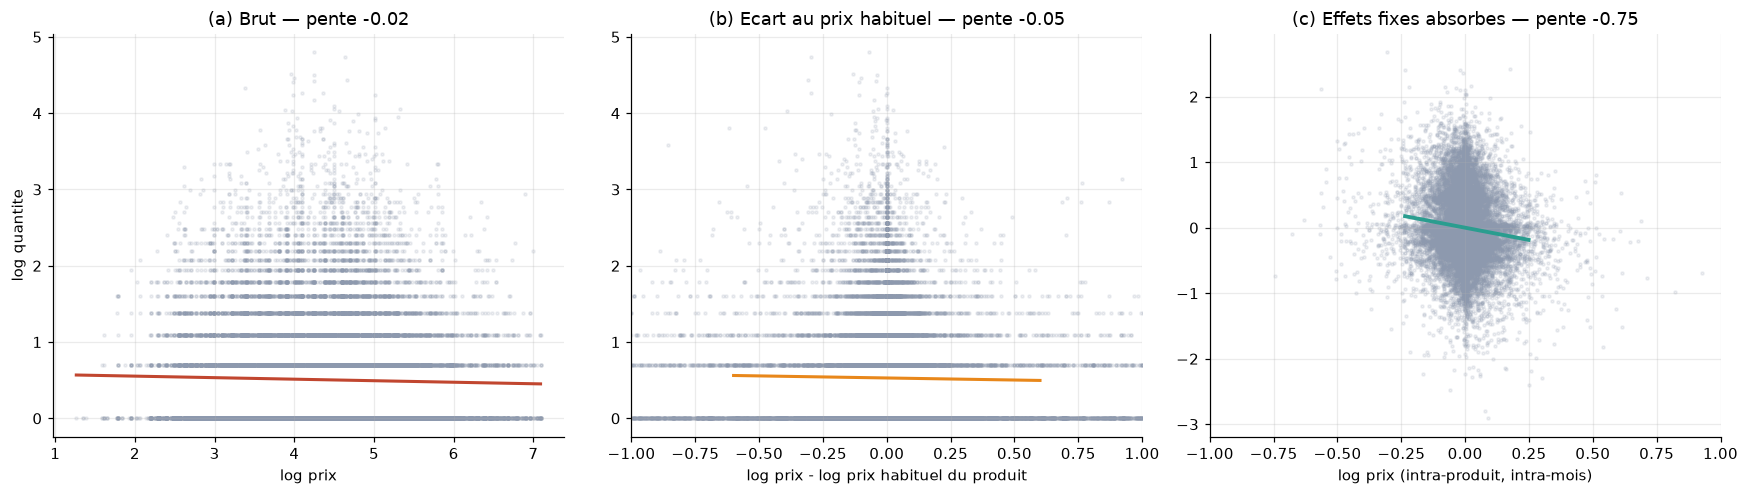

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

# (a) Brut : chaque point est une observation produit-mois
axes[0].scatter(panel_prod["log_price"], panel_prod["log_quantity"], s=4, alpha=0.15, color="#8D99AE")
coef = np.polyfit(panel_prod["log_price"], panel_prod["log_quantity"], 1)
xs = np.linspace(panel_prod["log_price"].min(), panel_prod["log_price"].max(), 50)
axes[0].plot(xs, np.polyval(coef, xs), color="#C1462F", lw=2)
axes[0].set_title(f"(a) Brut — pente {coef[0]:+.2f}")
axes[0].set_xlabel("log prix"); axes[0].set_ylabel("log quantite")

# (b) Prix relatif au produit : on retire l'effet "quel produit"
axes[1].scatter(panel_prod["price_rel_product"], panel_prod["log_quantity"], s=4, alpha=0.15, color="#8D99AE")
masque = panel_prod["price_rel_product"].abs() > 1e-6
coef_b = np.polyfit(panel_prod.loc[masque, "price_rel_product"], panel_prod.loc[masque, "log_quantity"], 1)
xs_b = np.linspace(-0.6, 0.6, 50)
axes[1].plot(xs_b, np.polyval(coef_b, xs_b), color="#E8871A", lw=2)
axes[1].set_xlim(-1, 1)
axes[1].set_title(f"(b) Ecart au prix habituel — pente {coef_b[0]:+.2f}")
axes[1].set_xlabel("log prix - log prix habituel du produit")

# (c) Apres absorption complete des effets fixes produit et mois
from optimization_pricing.elasticity import demean

work = panel_prod.reset_index(drop=True)
x_w = demean(work["log_price"], [work["product_id"], work["month"]])
y_w = demean(work["log_quantity"], [work["product_id"], work["month"]])
axes[2].scatter(x_w, y_w, s=4, alpha=0.15, color="#8D99AE")
coef_c = np.polyfit(x_w, y_w, 1)
xs_c = np.linspace(np.percentile(x_w, 1), np.percentile(x_w, 99), 50)
axes[2].plot(xs_c, np.polyval(coef_c, xs_c), color="#2A9D8F", lw=2.5)
axes[2].set_xlim(-1, 1)
axes[2].set_title(f"(c) Effets fixes absorbes — pente {coef_c[0]:+.2f}")
axes[2].set_xlabel("log prix (intra-produit, intra-mois)")

plt.tight_layout()
plt.show()

Trois nuages, trois pentes très différentes, **exactement les mêmes données**.

* **(a)** compare des produits différents : la pente n'a aucun sens causal.
* **(b)** commence à isoler l'écart au prix habituel : la pente se creuse.
* **(c)** absorbe entièrement l'identité du produit et l'effet du mois : c'est
  la seule pente qu'on peut appeler une élasticité.

C'est la démonstration visuelle de ce que le notebook 04 formalise.

## 5. Hétérogénéité entre catégories

Toutes les catégories ne se comportent pas pareil : ni en volume, ni en niveau
de prix, ni en intensité concurrentielle. C'est ce qui justifiera d'estimer une
élasticité **par catégorie** plutôt qu'une seule valeur globale.

In [9]:
from optimization_pricing.config import CATEGORY_COL

profil = (
    panel_prod.groupby(CATEGORY_COL)
    .agg(
        volume=("quantity", "sum"),
        prix_median=("price", "median"),
        produits=("product_id", "nunique"),
        variation_prix=("price_rel_product", lambda s: s.abs().mean()),
    )
    .sort_values("volume", ascending=False)
    .head(15)
)
profil

,volume,prix_median,produits,variation_prix
product_category_name_english,,,,
bed_bath_table,7390,70.250,642,0.139
health_beauty,6426,85.117,458,0.201
computers_accessories,5497,69.000,371,0.210
sports_leisure,5039,89.900,552,0.170
furniture_decor,4766,59.900,423,0.159
watches_gifts,4406,97.900,275,0.212
housewares,3673,59.900,387,0.197
garden_tools,3244,69.990,101,0.201
telephony,2935,27.990,276,0.183


## Ce que ce notebook établit

* Le marché est en **forte croissance** → la tendance doit être contrôlée.
* Le pic de **novembre** fait monter volume et prix ensemble → risque
  d'élasticité positive si on l'ignore.
* Une part importante des produits ne change **jamais** de prix ; les
  mouvements observés sont majoritairement des baisses, d'amplitude modérée.
* La relation prix/quantité **change de signe et d'ampleur** selon ce qu'on
  contrôle : c'est un problème d'identification, pas de visualisation.
* Les catégories sont très hétérogènes → élasticités par catégorie.

**Suite :** notebook 04, l'estimation formelle de l'élasticité.